In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error
)
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.exponential_smoothing.ets import ETSModel

In [2]:
data = pd.read_parquet('../data/processed/national_monthly_registrations.parquet')

data = data.sort_values('date').copy()
data['date'] = data['date'].dt.to_period('M')
data = data.set_index('date')


data['lag_1'] = data['bev'].shift(1)
data['lag_12'] = data['bev'].shift(12)

training_data = data.loc['2024':].copy()

y = training_data['bev']

test_start = '2026-01'
y_test = y.loc[test_start:]

hw_values = []
for date in y_test.index:

    # Only use observations before the prediction month
    history = y.loc[y.index < date]

    model = ExponentialSmoothing(
        history,
        trend='add',
        seasonal='add',
        seasonal_periods=12,
        initialization_method='estimated'
    )

    fitted = model.fit(optimized=True)

    hw_values.append(fitted.forecast(1).iloc[0])

hw_pred = pd.Series(hw_values, index=y_test.index)

naive_last_month_pred = data.loc[y_test.index, 'lag_1']
naive_last_year_pred = data.loc[y_test.index, 'lag_12']


predictions = {
    'Holt-Winters': hw_pred,
    'Naive last month': naive_last_month_pred,
    'Naive last year': naive_last_year_pred
}
results = pd.DataFrame({
    name : {
        'MAE': mean_absolute_error(y_test, pred),
        'MAPE (%)': mean_absolute_percentage_error(y_test, pred) * 100
    }
    for name, pred in predictions.items()
}).T

display(results)

,MAE,MAPE (%)
Holt-Winters,7422.484790,11.296639
Naive last month,12181.222222,17.722361
Naive last year,24660.222222,34.706233


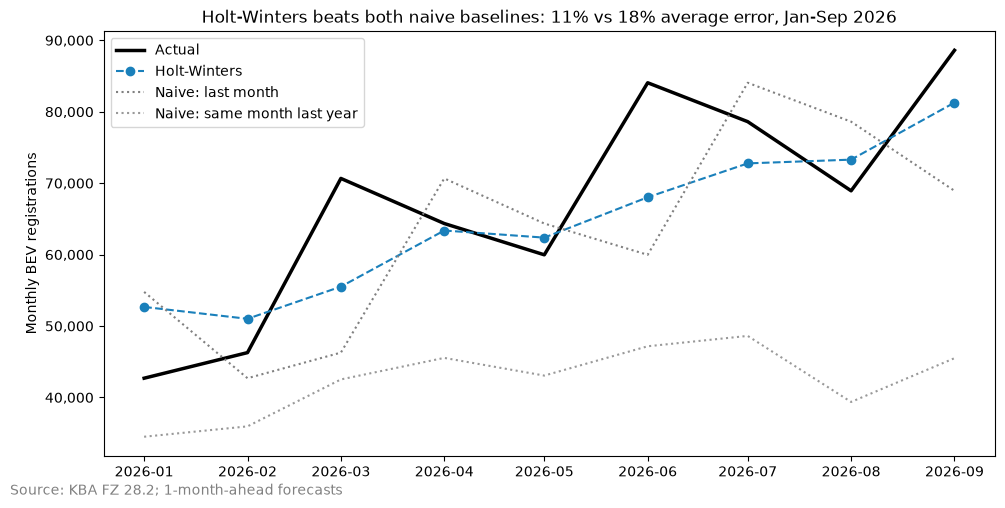

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))

dates = y_test.index.to_timestamp()

ax.plot(dates, y_test.values, label='Actual', linewidth=2.5, color='black')
ax.plot(dates, hw_pred.values, label='Holt-Winters', color='#1a80bb', linestyle='--', marker='o')
ax.plot(dates, naive_last_month_pred.values, label='Naive: last month', color='grey', linestyle=':')
ax.plot(dates, naive_last_year_pred.values, label="Naive: same month last year", color='#999999', linestyle=':')

ax.legend()
ax.set(
    title="Holt-Winters beats both naive baselines: 11% vs 18% average error, Jan-Sep 2026",
    ylabel="Monthly BEV registrations"
)

ax.yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter('{x:,.0f}'))

fig.text(0, 0, "Source: KBA FZ 28.2; 1-month-ahead forecasts", color='grey')
plt.tight_layout()
fig.savefig('../reports/figures/bev_forecast_backtest.png', dpi=150, bbox_inches='tight')
plt.show()

In [4]:
final_model = ETSModel(y, error='add', trend='add',
                       seasonal='add', seasonal_periods=12)

final_fit = final_model.fit()


forecast = final_fit.get_prediction(start='2026-10', end='2026-12').summary_frame(alpha=0.05)

for i in range(len(forecast)):
    assert forecast['pi_lower'].iloc[i] < forecast['mean'].iloc[i] < forecast['pi_upper'].iloc[i]

display(
    forecast
)

,mean,pi_lower,pi_upper
2026-10,93664.157186,80501.270962,106827.043410
2026-11,97561.075596,83240.329357,111881.821835
2026-12,98474.754681,82570.472332,114379.037029


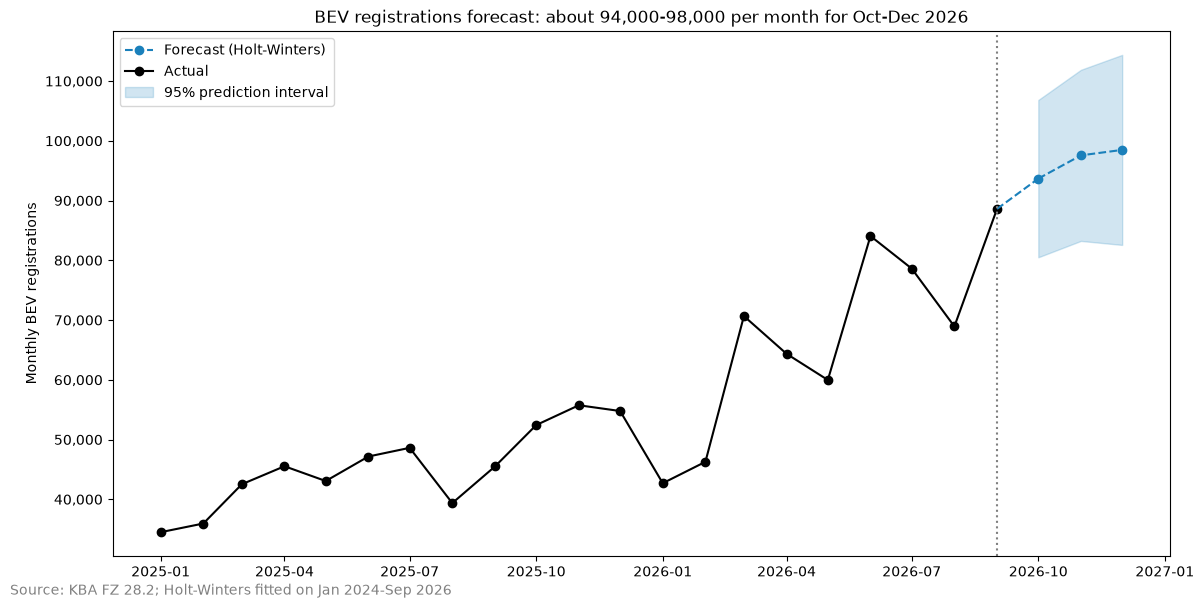

In [5]:
fig, ax = plt.subplots(figsize=(12,6))

forecast_plot_data = forecast.copy()
actual = y.loc['2025-01':].copy()
actual.index = actual.index.to_timestamp()

forecast_plot_data.index = forecast_plot_data.index.to_timestamp()

ax.plot(forecast_plot_data['mean'], linestyle='--', marker='o', color='#1a80bb', label='Forecast (Holt-Winters)')
ax.plot(actual, marker='o', color='black', label='Actual')

ax.plot([actual.index[-1], forecast_plot_data.index[0]], 
        [actual.iloc[-1], forecast_plot_data['mean'].iloc[0]],
         color='#1a80bb', linestyle='--'
        )

ax.fill_between(forecast_plot_data.index, forecast_plot_data['pi_lower'], forecast_plot_data['pi_upper'], 
                color='#1a80bb', alpha=0.2, label='95% prediction interval')

ax.axvline(actual.index[-1], color='grey', linestyle=':')

ax.legend()

ax.set_title("BEV registrations forecast: about 94,000-98,000 per month for Oct-Dec 2026")
ax.set_ylabel("Monthly BEV registrations")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter('{x:,.0f}'))
fig.text(0, 0, "Source: KBA FZ 28.2; Holt-Winters fitted on Jan 2024-Sep 2026", color='grey')

plt.tight_layout()
fig.savefig('../reports/figures/bev_forecast_q4_2026.png', dpi=150, bbox_inches='tight')
plt.show()

### Summary: monthly BEV forecast

**Question:** can a simple time series model forecast national monthly BEV registrations better than naive rules?

**Data and window:** national monthly BEV registrations (KBA FZ 28.2), January 2024 to September 2026 (33 months). Earlier months are excluded because the BEV bonus ended in December 2023, which caused a spike and a crash. The market before and after behaves differently.

**Backtest (January–September 2026):** rolling 1-month-ahead forecasts. For each test month, the model was fitted only on the months before it.

| Method | MAE (BEVs) | MAPE |
|---|---|---|
| Holt-Winters (additive trend and seasonality) | ≈ 7,400 | 11.3% |
| Naive: last month | ≈ 12,200 | 17.7% |
| Naive: same month last year | ≈ 24,700 | 34.7% |

- Holt-Winters reduces the error of the best baseline by about 40%.
- "Same month last year" is far too low every month, because BEV registrations grew strongly from 2025 to 2026.
- Holt-Winters follows the trend but underestimates the quarter-end peaks (March, June, September).

**Forecast, October–December 2026** (ETS model with the same settings, fitted on all 33 months):

| Month | Forecast | 95% prediction interval |
|---|---|---|
| October 2026 | ≈ 93,700 | 80,500 – 106,800 |
| November 2026 | ≈ 97,600 | 83,200 – 111,900 |
| December 2026 | ≈ 98,500 | 82,600 – 114,400 |

**Limitations:**
- Only 33 months of data, so the 12-month seasonal pattern is estimated from less than three cycles.
- In 2026, the months after a quarter-end peak dropped (April, July). The model forecasts October above September without that dip, so October is the most likely month to come in lower than forecast.
- The model uses only past BEV registrations. External factors such as subsidies, new models and price changes are not included.